# K-M 复势点力基本解富集 PIKFNN：I 型边缘裂纹

## 上半域模型：$0\le x\le b,\ 0\le y\le h/2$

本 notebook 模仿前面的中心裂纹 K-M PIKFNN 算例，但将几何改为**单边缘裂纹板**：

- 板宽：$b$；
- 板总高：$h$；
- 裂纹从左边界沿 $y=0$ 向右延伸，裂纹长度为 $a$；
- 上、下端承受远场拉应力 $\sigma_{22}=\sigma_0$；
- 左、右侧边界均为自由边界；
- 裂纹关于 $y=0$ 为 I 型对称，因此只计算**上半部分**；
- 裂尖坐标为 $(a,0)$；
- 近裂尖使用单位 $K_I$ 渐近场作为显式富集项；
- 普通场由域外 K-M 点力基本解线性组合表示，因此不需要 PDE 内点残差。

上半域的五组边界条件为：

| 边界 | 位置 | 条件 |
|---|---|---|
| `top` | $y=h/2$ | $\sigma_{yy}=\sigma_0,\ \sigma_{xy}=0$ |
| `right` | $x=b$ | $\sigma_{xx}=0,\ \sigma_{xy}=0$ |
| `left` | $x=0,\ y>0$ | $\sigma_{xx}=0,\ \sigma_{xy}=0$ |
| `crack` | $y=0^+,\ 0<x<a$ | $\sigma_{yy}=0,\ \sigma_{xy}=0$ |
| `ligament` | $y=0,\ a<x<b$ | $u_y=0,\ \sigma_{xy}=0$ |

注意：与中心裂纹四分之一模型不同，`left` 在这里是**真实自由边界**，不是对称边界。

## 1. 导入库与参数配置

默认采用：

\[
a=1,\qquad b=2,\qquad h=6,\qquad \sigma_0=1.
\]

其中 `h` 表示整块板的总高度，因此本模型计算高度为

\[
H=h/2=3.
\]

裂尖局部 MFS 源默认只放一圈 $r_s=0.08a$，与前面的单圆弧中心裂纹版本保持一致。

In [41]:
import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# K-M / MFS 核矩阵可能病态，统一使用双精度。
torch.set_default_dtype(torch.float64)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = {
    # Geometry / material / loading
    "a": 0.5,
    "b": 1.0,
    "h": 2.0,              # total height; upper-half height H=h/2
    "E": 1.0,
    "nu": 0.30,
    "sigma0": 1.0,
    "plane_strain": True,

    # Boundary collocation
    "n_top": 121,
    "n_side": 121,
    "n_crack": 120,
    "n_ligament": 120,

    # Near-tip refinement
    "r_min": 1.0e-4,
    "r_transition": 0.20,
    "eps_crack": 1.0e-8,

    # Exterior source points
    "n_src_side": 64,
    "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.10,

    # Local source ring(s) below crack tip
    "tip_cluster_count": 32,
    "tip_cluster_radii": [0.06],
    "tip_cluster_angle_min_deg": 200.0,
    "tip_cluster_angle_max_deg": 340.0,

    # Optimization
    "adam_steps": 1500,
    "adam_lr": 1.0e-2,
    "lbfgs_epochs": 350,
    "lbfgs_max_iter": 20,
    "adam_print_every": 100,
    "lbfgs_print_every": 20,

    # Boundary loss weights
    "w_top": 2.5,
    "w_right": 1.5,
    "w_left": 1.5,
    "w_crack": 8.0,
    "w_ligament": 4.0,
    "lambda_reg": 1.0e-10,

    # Linear algebra diagnostic
    "svd_rtol": 1.0e-10,

    # Post-processing
    "nx_plot": 181,
    "ny_plot_half": 181,
    "plot_percentile": 99.0,
    "seed": 2026,
}

torch.manual_seed(cfg["seed"])
np.random.seed(cfg["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(cfg["seed"])

print("device =", device)

device = cuda


## 2. 材料常数与边缘裂纹参考 $K_I$

采用

\[
\mu=\frac{E}{2(1+\nu)}.
\]

平面应变下

\[
\kappa=3-4\nu.
\]

为了检查数值结果，这里使用一个常见的有限宽度单边裂纹近似：

\[
K_I=\sigma_0\sqrt{\pi a}\,F(a/b),
\]

\[
F(\alpha)=
1.12-0.231\alpha+10.55\alpha^2-21.72\alpha^3+30.39\alpha^4.
\]

该公式只用于训练后的误差评价，不进入训练损失。
如果你之后有 Fig.10 对应论文给出的专用参考公式，可直接替换 `reference_ki_edge()`。

In [42]:
E = cfg["E"]
nu = cfg["nu"]
a = cfg["a"]
b = cfg["b"]
h = cfg["h"]
H = 0.5 * h
sigma0 = cfg["sigma0"]

mu = E / (2.0 * (1.0 + nu))

if cfg["plane_strain"]:
    kappa = 3.0 - 4.0 * nu
else:
    kappa = (3.0 - nu) / (1.0 + nu)


def reference_ki_edge(a_value=a, b_value=b, sigma=sigma0):
    """Common finite-width single-edge-crack correction."""
    alpha = a_value / b_value
    F = (
        1.12
        - 0.231 * alpha
        + 10.55 * alpha**2
        - 21.72 * alpha**3
        + 30.39 * alpha**4
    )
    return sigma * math.sqrt(math.pi * a_value) * F


KI_REF = reference_ki_edge()

print(f"mu      = {mu:.10f}")
print(f"kappa   = {kappa:.10f}")
print(f"H=h/2   = {H:.10f}")
print(f"a/b     = {a/b:.6f}")
print(f"K_I ref = {KI_REF:.10f}")

mu      = 0.3846153846
kappa   = 1.8000000000
H=h/2   = 1.0000000000
a/b     = 0.500000
K_I ref = 3.5423357449


## 3. 上半域边界配点

裂纹和裂尖前方韧带均采用“远处均匀 + 裂尖附近几何加密”。

裂纹面和韧带都不取恰好位于裂尖的点，避免直接在 $r=0$ 处计算奇异应力。

In [43]:
def linspace_col(x0: float, x1: float, n: int) -> torch.Tensor:
    return torch.linspace(x0, x1, n, device=device).reshape(-1, 1)


def geometric_distances(r_min: float, r_transition: float, n_near: int) -> torch.Tensor:
    """Logarithmically clustered distances from the crack tip."""
    return torch.logspace(
        math.log10(r_min),
        math.log10(r_transition),
        n_near,
        device=device,
    )


def generate_boundary_points():
    eps = cfg["eps_crack"]
    pts = {}

    # 1) Top: y=H, remote tension.
    x_top = linspace_col(0.0, b, cfg["n_top"])
    pts["top"] = torch.cat(
        [x_top, torch.full_like(x_top, H)],
        dim=1,
    )

    # 2) Right free edge: x=b.
    y_right = linspace_col(0.0, H, cfg["n_side"])
    pts["right"] = torch.cat(
        [torch.full_like(y_right, b), y_right],
        dim=1,
    )

    # 3) Left REAL free edge: x=0, y>0.
    # Start slightly above the crack mouth to avoid duplicating (0,0).
    y_left = linspace_col(0.01 * H, H, cfg["n_side"])
    pts["left"] = torch.cat(
        [torch.zeros_like(y_left), y_left],
        dim=1,
    )

    # 4) Crack face: 0<x<a, y=0+.
    n_near_c = cfg["n_crack"] // 2
    n_far_c = cfg["n_crack"] - n_near_c

    rc = geometric_distances(
        cfg["r_min"],
        cfg["r_transition"],
        n_near_c,
    ) * a

    x_near_c = a - torch.flip(rc, dims=[0])

    x_far_c = torch.linspace(
        0.01 * a,
        (1.0 - cfg["r_transition"]) * a,
        n_far_c,
        device=device,
    )

    xc = torch.unique(
        torch.cat([x_far_c, x_near_c]),
        sorted=True,
    ).reshape(-1, 1)

    pts["crack"] = torch.cat(
        [xc, torch.full_like(xc, +eps)],
        dim=1,
    )

    # 5) Ligament: a<x<b, y=0.
    # Mode-I symmetry: uy=0, sigma_xy=0.
    n_near_l = cfg["n_ligament"] // 2
    n_far_l = cfg["n_ligament"] - n_near_l

    rl = geometric_distances(
        cfg["r_min"],
        cfg["r_transition"],
        n_near_l,
    ) * a

    x_near_l = a + rl

    x_far_l = torch.linspace(
        (1.0 + cfg["r_transition"]) * a,
        b,
        n_far_l,
        device=device,
    )

    xl = torch.unique(
        torch.cat([x_near_l, x_far_l]),
        sorted=True,
    ).reshape(-1, 1)

    pts["ligament"] = torch.cat(
        [xl, torch.zeros_like(xl)],
        dim=1,
    )

    return pts


bnd_pts = generate_boundary_points()

print("Boundary collocation counts")
print("-" * 46)
for key, value in bnd_pts.items():
    print(f"{key:12s}: {value.shape[0]:4d}")
print("-" * 46)
print("total records:", sum(v.shape[0] for v in bnd_pts.values()))
print("nearest crack point to tip    =", a - bnd_pts["crack"][-1, 0].item())
print("nearest ligament point to tip =", bnd_pts["ligament"][0, 0].item() - a)

Boundary collocation counts
----------------------------------------------
top         :  121
right       :  121
left        :  121
crack       :  119
ligament    :  119
----------------------------------------------
total records: 601
nearest crack point to tip    = 4.999999999999449e-05
nearest ligament point to tip = 4.999999999999449e-05


## 4. 域外点力源与裂尖局部源

外围源点放在包围上半域

\[
0\le x\le b,\qquad 0\le y\le H
\]

的虚拟矩形边界上。

裂尖附近额外在 $(a,0)$ 下方放置一圈局部 MFS 源：

\[
r_s=0.08a,\qquad
\theta_s\in[200^\circ,340^\circ].
\]

这些局部点仍然属于普通 MFS 点力源，不是 $K_I$ 富集项本身的“源点”。

In [44]:
def generate_source_points() -> torch.Tensor:
    mx = cfg["src_margin_x_factor"] * b
    my = cfg["src_margin_y_factor"] * H
    n = cfg["n_src_side"]

    xs = torch.linspace(-mx, b + mx, n, device=device)
    ys = torch.linspace(-my, H + my, n, device=device)

    src = []

    # Outer fictitious rectangle: top + bottom.
    for x in xs:
        src.append(torch.stack([x, torch.tensor(-my, device=device)]))
        src.append(torch.stack([x, torch.tensor(H + my, device=device)]))

    # Left + right. Exclude corners to avoid duplicates.
    for y in ys[1:-1]:
        src.append(torch.stack([torch.tensor(-mx, device=device), y]))
        src.append(torch.stack([torch.tensor(b + mx, device=device), y]))

    # Local ring(s) below crack tip.
    count = cfg["tip_cluster_count"]
    if count > 0:
        angles = torch.linspace(
            math.radians(cfg["tip_cluster_angle_min_deg"]),
            math.radians(cfg["tip_cluster_angle_max_deg"]),
            count,
            device=device,
        )

        for radius_factor in cfg["tip_cluster_radii"]:
            radius = radius_factor * a

            for theta in angles:
                sx = a + radius * torch.cos(theta)
                sy = radius * torch.sin(theta)

                # Physical upper-half domain is y>=0, so local sources must stay below it.
                if sy < -1.0e-8:
                    src.append(torch.stack([sx, sy]))

    return torch.stack(src, dim=0)


src_pts = generate_source_points()

outer_source_count = 4 * cfg["n_src_side"] - 4
local_source_count = int(src_pts.shape[0]) - outer_source_count

print("outer sources =", outer_source_count)
print("local sources =", local_source_count)
print("total sources =", src_pts.shape[0])
print("expected trainable parameters =", 2 * src_pts.shape[0] + 1)

outer sources = 252
local sources = 32
total sources = 284
expected trainable parameters = 569


## 5. 边界点与源点分布图

运行本单元后应确认：

- 物理域是上半矩形；
- 裂纹从左边界 $(0,0)$ 延伸到 $(a,0)$；
- 所有普通 MFS 源都位于上半物理域之外；
- 局部圆弧源位于裂尖下方。

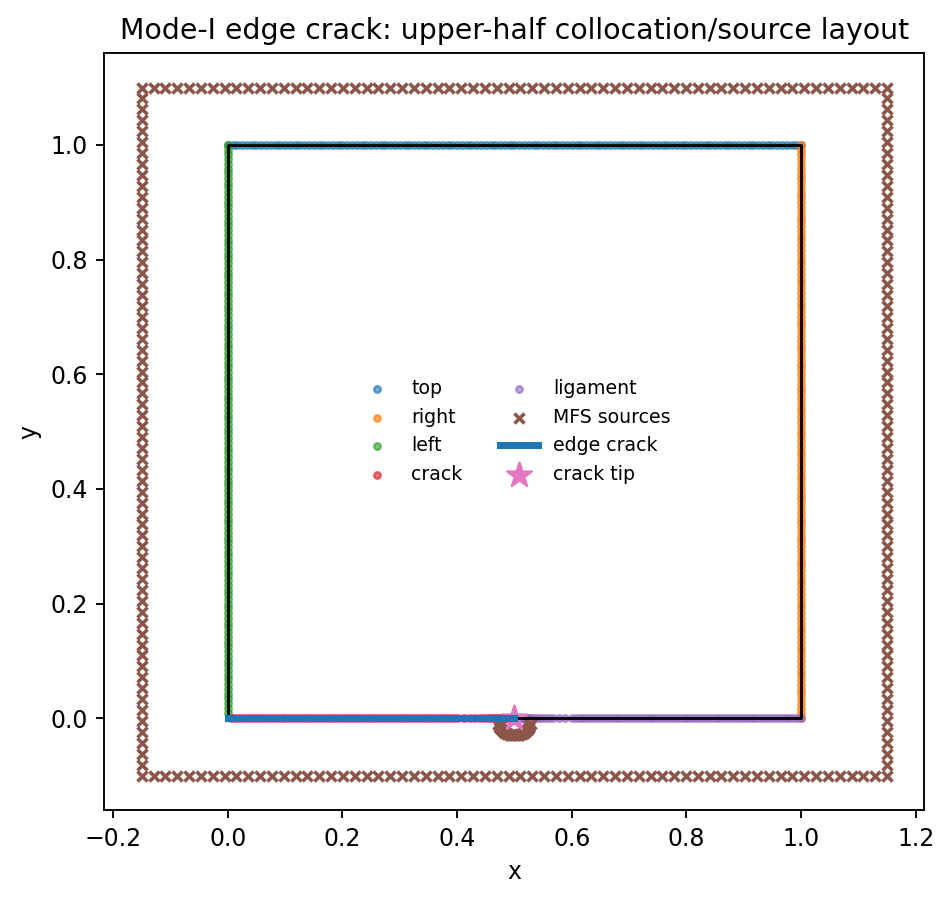

In [45]:
fig, ax = plt.subplots(figsize=(7.0, 5.4), dpi=170)

# Upper-half physical rectangle.
ax.plot([0, b, b, 0, 0], [0, 0, H, H, 0], "k-", lw=1.2)

for key, pts in bnd_pts.items():
    p = pts.detach().cpu().numpy()
    ax.scatter(p[:, 0], p[:, 1], s=8, alpha=0.62, label=key)

s = src_pts.detach().cpu().numpy()
ax.scatter(
    s[:, 0],
    s[:, 1],
    marker="x",
    s=18,
    label="MFS sources",
)

ax.plot([0, a], [0, 0], lw=3.0, label="edge crack")
ax.scatter([a], [0], marker="*", s=120, label="crack tip")

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Mode-I edge crack: upper-half collocation/source layout")
ax.legend(frameon=False, fontsize=8, ncol=2)

fig.tight_layout()
plt.show()

## 6. Kolosov–Muskhelishvili 位移—应力公式

采用与前面中心裂纹代码一致的 K-M 约定：

\[
\sigma_{xx}+\sigma_{yy}=4\operatorname{Re}\Phi'(z),
\]

\[
\sigma_{yy}-\sigma_{xx}+2i\sigma_{xy}
=
2\left(\bar z\,\Phi''(z)+\Psi'(z)\right),
\]

\[
2\mu(u_x+i u_y)
=
\kappa\Phi-z\overline{\Phi'}-\overline{\Psi}.
\]

In [46]:
def km_response(
    z: torch.Tensor,
    phi: torch.Tensor,
    dphi: torch.Tensor,
    ddphi: torch.Tensor,
    psi: torch.Tensor,
    dpsi: torch.Tensor,
):
    """Return ux, uy, sigma_xx, sigma_yy, sigma_xy."""

    stress_sum = 4.0 * torch.real(dphi)

    stress_diff_complex = 2.0 * (
        torch.conj(z) * ddphi + dpsi
    )

    stress_diff = torch.real(stress_diff_complex)

    sigma_xy = 0.5 * torch.imag(stress_diff_complex)
    sigma_xx = 0.5 * (stress_sum - stress_diff)
    sigma_yy = 0.5 * (stress_sum + stress_diff)

    displacement_complex = (
        kappa * phi
        - z * torch.conj(dphi)
        - torch.conj(psi)
    ) / (2.0 * mu)

    ux = torch.real(displacement_complex)
    uy = torch.imag(displacement_complex)

    return ux, uy, sigma_xx, sigma_yy, sigma_xy

## 7. K-M 点力基本解

每个源点 $\zeta_j$ 放置两个独立单位点力：

\[
(F_x,F_y)=(1,0),\qquad
(F_x,F_y)=(0,1).
\]

因此每个源点对应两个普通核系数。

如果源点总数为 $N_s$，再加一个 $K_I$ 富集系数，则

\[
N_{\rm train}=2N_s+1.
\]

In [47]:
def complex_point_force_potential_response(
    x: torch.Tensor,
    y: torch.Tensor,
    sx: torch.Tensor,
    sy: torch.Tensor,
    fx: float,
    fy: float,
    add_kelvin_constant: bool = True,
):
    """
    K-M complex-potential form of the 2D point-force fundamental solution.

    P = Fx + i Fy
    q = z - zeta

    Phi = -P/[2*pi*(kappa+1)] * log(q)

    Psi = kappa*conj(P)/[2*pi*(kappa+1)] * log(q)
          + P*conj(zeta)/[2*pi*(kappa+1)] / q
    """

    z = torch.complex(
        x.reshape(-1),
        y.reshape(-1),
    )

    zeta = torch.complex(
        sx.reshape(()),
        sy.reshape(()),
    )

    p_force = torch.as_tensor(
        complex(fx, fy),
        dtype=z.dtype,
        device=device,
    )

    q = z - zeta
    den = 2.0 * math.pi * (kappa + 1.0)

    logq = torch.log(q)

    phi = -p_force / den * logq
    dphi = -p_force / den / q
    ddphi = p_force / den / (q * q)

    psi = (
        kappa * torch.conj(p_force) / den * logq
        + p_force * torch.conj(zeta) / den / q
    )

    dpsi = (
        kappa * torch.conj(p_force) / den / q
        - p_force * torch.conj(zeta) / den / (q * q)
    )

    # Rigid-displacement normalization constant; stresses are unchanged.
    if add_kelvin_constant:
        phi = phi + p_force / (
            2.0 * math.pi * kappa * (kappa + 1.0)
        )

    return km_response(
        z,
        phi,
        dphi,
        ddphi,
        psi,
        dpsi,
    )

## 8. I 型裂尖渐近富集项

裂尖位于

\[
(x_{\rm tip},y_{\rm tip})=(a,0).
\]

这里构造单位 $K_I$ 的标准 I 型近场，因此最后一列核函数前的可训练系数就是物理上的 $K_I$。

In [48]:
def mode_i_tip_response(
    x: torch.Tensor,
    y: torch.Tensor,
):
    """Unit-KI Mode-I crack-tip field at (a,0)."""

    xl = x.reshape(-1) - a
    yl = y.reshape(-1)

    r = torch.sqrt(
        torch.clamp(
            xl * xl + yl * yl,
            min=1.0e-30,
        )
    )

    theta = torch.atan2(yl, xl)

    c2 = torch.cos(0.5 * theta)
    s2 = torch.sin(0.5 * theta)
    s32 = torch.sin(1.5 * theta)
    c32 = torch.cos(1.5 * theta)

    root = torch.sqrt(r / (2.0 * math.pi))
    inv_root = 1.0 / torch.sqrt(2.0 * math.pi * r)

    ux = (
        root
        * c2
        * (kappa - 1.0 + 2.0 * s2 * s2)
        / (2.0 * mu)
    )

    uy = (
        root
        * s2
        * (kappa + 1.0 - 2.0 * c2 * c2)
        / (2.0 * mu)
    )

    sigma_xx = (
        inv_root
        * c2
        * (1.0 - s2 * s32)
    )

    sigma_yy = (
        inv_root
        * c2
        * (1.0 + s2 * s32)
    )

    sigma_xy = (
        inv_root
        * s2
        * c2
        * c32
    )

    return ux, uy, sigma_xx, sigma_yy, sigma_xy


Q_NAMES = ("ux", "uy", "sxx", "syy", "sxy")


def build_kernel_columns(points: torch.Tensor, sources: torch.Tensor):
    """Each source contributes one Fx column and one Fy column."""

    x = points[:, 0:1]
    y = points[:, 1:2]

    cols = {q: [] for q in Q_NAMES}

    def add_response(resp):
        for q, value in zip(Q_NAMES, resp):
            cols[q].append(value.reshape(-1))

    for source in sources:
        add_response(
            complex_point_force_potential_response(
                x, y,
                source[0], source[1],
                1.0, 0.0,
            )
        )

        add_response(
            complex_point_force_potential_response(
                x, y,
                source[0], source[1],
                0.0, 1.0,
            )
        )

    return {
        q: torch.stack(values, dim=1)
        for q, values in cols.items()
    }


def build_tip_columns(points: torch.Tensor):
    """One additional column corresponding to unit KI."""

    resp = mode_i_tip_response(
        points[:, 0:1],
        points[:, 1:2],
    )

    return {
        q: value.reshape(-1)
        for q, value in zip(Q_NAMES, resp)
    }

## 9. 组装加权边界线性系统

总参数向量：

\[
\mathbf c=
[c_1,\ldots,c_{2N_s},K_I]^T.
\]

为了改善 L-BFGS 的尺度问题，先用完整加权边界系统计算每一列范数 `col_scale`。

In [49]:
BASIS_KEYS = (
    "top",
    "right",
    "left",
    "crack",
    "ligament",
)

basis = {
    key: build_kernel_columns(
        bnd_pts[key],
        src_pts,
    )
    for key in BASIS_KEYS
}

tip_basis = {
    key: build_tip_columns(
        bnd_pts[key]
    )
    for key in BASIS_KEYS
}

n_kernel = 2 * int(src_pts.shape[0])
n_total_params = n_kernel + 1

print("ordinary kernel coefficients =", n_kernel)
print("K_I coefficient              = 1")
print("total trainable parameters   =", n_total_params)


def physical_row(key: str, quantity: str, include_tip: bool = True):
    n = bnd_pts[key].shape[0]

    A = torch.zeros(
        (n, n_total_params),
        device=device,
    )

    A[:, :n_kernel] = basis[key][quantity]

    if include_tip:
        A[:, -1] = tip_basis[key][quantity]

    return A


A_rows = []
b_rows = []
row_names = []


def add_linear_block(A, target, weight, name):
    """
    weight*mean(residual^2) is equivalent to
    ||sqrt(weight/n)*(A c-b)||_2^2.
    """
    n = A.shape[0]
    fac = math.sqrt(weight / n)

    A_rows.append(fac * A)

    if torch.is_tensor(target):
        t = target.reshape(-1, 1).to(
            device=device,
            dtype=A.dtype,
        )
    else:
        t = torch.full(
            (n, 1),
            float(target),
            device=device,
            dtype=A.dtype,
        )

    b_rows.append(fac * t)
    row_names.append((name, n))


# Top: sigma_yy=sigma0, sigma_xy=0
add_linear_block(physical_row("top", "syy"), sigma0, cfg["w_top"], "top_syy")
add_linear_block(physical_row("top", "sxy"), 0.0, cfg["w_top"], "top_sxy")

# Right free edge: sigma_xx=0, sigma_xy=0
add_linear_block(physical_row("right", "sxx"), 0.0, cfg["w_right"], "right_sxx")
add_linear_block(physical_row("right", "sxy"), 0.0, cfg["w_right"], "right_sxy")

# Left real free edge: sigma_xx=0, sigma_xy=0
add_linear_block(physical_row("left", "sxx"), 0.0, cfg["w_left"], "left_sxx")
add_linear_block(physical_row("left", "sxy"), 0.0, cfg["w_left"], "left_sxy")

# Crack face: sigma_yy=0, sigma_xy=0
add_linear_block(physical_row("crack", "syy"), 0.0, cfg["w_crack"], "crack_syy")
add_linear_block(physical_row("crack", "sxy"), 0.0, cfg["w_crack"], "crack_sxy")

# Ligament symmetry: uy=0, sigma_xy=0
add_linear_block(physical_row("ligament", "uy"), 0.0, cfg["w_ligament"], "ligament_uy")
add_linear_block(physical_row("ligament", "sxy"), 0.0, cfg["w_ligament"], "ligament_sxy")


A_phys = torch.cat(A_rows, dim=0)
b_phys = torch.cat(b_rows, dim=0)

col_scale = torch.linalg.norm(A_phys, dim=0).detach()

col_scale = torch.where(
    col_scale > 0.0,
    col_scale,
    torch.ones_like(col_scale),
)

A_norm = A_phys / col_scale.reshape(1, -1)

print("A shape =", tuple(A_norm.shape))
print("column scale range =", col_scale.min().item(), col_scale.max().item())

ordinary kernel coefficients = 568
K_I coefficient              = 1
total trainable parameters   = 569
A shape = (1202, 569)
column scale range = 0.6045637489368018 16.57418387308159


## 10. SVD 可辨识性诊断

用于检查当前源点配置是否存在严重列相关。

重点看：

- `numerical rank`
- `nullity`
- `cond. estimate`

如果后续增加很多局部源点而 `nullity` 明显增加，说明普通 MFS 核与裂尖富集项之间可能出现较强耦合。

In [50]:
with torch.no_grad():
    sv = torch.linalg.svdvals(
        A_norm.detach().cpu()
    )

    threshold = cfg["svd_rtol"] * sv.max()

    numerical_rank = int(
        torch.sum(sv > threshold).item()
    )

    nullity = n_total_params - numerical_rank

    kept = sv[sv > threshold]

    cond_est = (
        (kept.max() / kept.min()).item()
        if kept.numel()
        else float("inf")
    )

print("\n=== Linear-system identifiability diagnostic ===")
print("A shape        :", tuple(A_norm.shape))
print("numerical rank :", numerical_rank)
print("nullity        :", nullity)
print("cond. estimate :", f"{cond_est:.6e}")
print("sv_max         :", f"{sv.max().item():.6e}")
print("sv_threshold   :", f"{threshold.item():.6e}")


=== Linear-system identifiability diagnostic ===
A shape        : (1202, 569)
numerical rank : 467
nullity        : 102
cond. estimate : 9.691992e+09
sv_max         : 1.137008e+01
sv_threshold   : 1.137008e-09


## 11. PIKFNN 系数模型

这里的可训练参数并不是 MLP 权重，而是：

\[
[\text{所有普通点力核系数},\ K_I].
\]

最后一个物理系数就是 $K_I$。

In [51]:
class EdgeCrackModeIPIKFNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.theta = nn.Parameter(
            torch.zeros(
                n_total_params,
                device=device,
            )
        )

        # Only an initialization, not a supervised target.
        ki_guess = 1.12 * sigma0 * math.sqrt(math.pi * a)

        with torch.no_grad():
            self.theta[-1] = (
                ki_guess * col_scale[-1]
            )

    def physical_coeffs(self):
        c = self.theta / col_scale

        kernel = c[:n_kernel]
        ki = c[-1]

        return kernel, ki

    def quantity(self, key: str, q: str, include_tip: bool = True):
        kernel, ki = self.physical_coeffs()

        value = basis[key][q] @ kernel

        if include_tip:
            value = value + tip_basis[key][q] * ki

        return value

    def kernel_regularization(self):
        kernel, _ = self.physical_coeffs()
        return torch.mean(kernel * kernel)


model = EdgeCrackModeIPIKFNN().to(device)

print("initial K_I =", model.physical_coeffs()[1].detach().item())

initial K_I = 1.4037118337933603


## 12. 边界损失

因为 K-M 点力基本解和裂尖渐近项在物理域内都满足二维无体力线弹性平衡方程，所以这里只需要边界条件 loss。

In [52]:
def mse(x):
    return torch.mean(x * x)


def loss_components(net: EdgeCrackModeIPIKFNN):
    L = {}

    # Top remote tension.
    L["top"] = cfg["w_top"] * (
        mse(net.quantity("top", "syy") - sigma0)
        + mse(net.quantity("top", "sxy"))
    )

    # Right free edge.
    L["right"] = cfg["w_right"] * (
        mse(net.quantity("right", "sxx"))
        + mse(net.quantity("right", "sxy"))
    )

    # Left real free edge.
    L["left"] = cfg["w_left"] * (
        mse(net.quantity("left", "sxx"))
        + mse(net.quantity("left", "sxy"))
    )

    # Crack face.
    L["crack"] = cfg["w_crack"] * (
        mse(net.quantity("crack", "syy"))
        + mse(net.quantity("crack", "sxy"))
    )

    # Ligament Mode-I symmetry.
    L["ligament"] = cfg["w_ligament"] * (
        mse(net.quantity("ligament", "uy"))
        + mse(net.quantity("ligament", "sxy"))
    )

    # Weak Tikhonov regularization for ordinary kernel coefficients only.
    L["reg"] = cfg["lambda_reg"] * net.kernel_regularization()

    total = sum(L.values())

    return total, L


def print_loss_components(net, prefix=""):
    total, L = loss_components(net)
    ki = net.physical_coeffs()[1].detach().item()

    print(prefix + f"total={total.detach().item():.8e} KI={ki:.10f}")

    for key in ("top", "right", "left", "crack", "ligament", "reg"):
        print(f"  {key:10s}: {L[key].detach().item():.8e}")

    return total, L


print_loss_components(model, prefix="Initial ")

Initial total=1.17250732e+00 KI=1.4037118338
  top       : 6.20398685e-01
  right     : 3.70161608e-01
  left      : 1.81947025e-01
  crack     : 7.99098075e-13
  ligament  : 0.00000000e+00
  reg       : 0.00000000e+00


(tensor(1.1725, device='cuda:0', grad_fn=<AddBackward0>),
 {'top': tensor(0.6204, device='cuda:0', grad_fn=<MulBackward0>),
  'right': tensor(0.3702, device='cuda:0', grad_fn=<MulBackward0>),
  'left': tensor(0.1819, device='cuda:0', grad_fn=<MulBackward0>),
  'crack': tensor(7.9910e-13, device='cuda:0', grad_fn=<MulBackward0>),
  'ligament': tensor(0., device='cuda:0', grad_fn=<MulBackward0>),
  'reg': tensor(0., device='cuda:0', grad_fn=<MulBackward0>)})

## 13. Adam + L-BFGS 训练

默认：

- Adam：1500 步；
- L-BFGS：350 个外层 epoch。

如需与中心裂纹代码做严格计算成本比较，可进一步统一优化步数、权重和边界点规模。

In [53]:
history = {
    "step": [],
    "total": [],
    "KI": [],
}


def record(step):
    total, _ = loss_components(model)
    ki = model.physical_coeffs()[1].detach().item()

    history["step"].append(step)
    history["total"].append(total.detach().item())
    history["KI"].append(ki)

    return total, ki


def train_model():
    global_step = 0
    t0 = time.time()

    # Adam warm start.
    if cfg["adam_steps"] > 0:
        opt_adam = torch.optim.Adam(
            model.parameters(),
            lr=cfg["adam_lr"],
        )

        for it in range(1, cfg["adam_steps"] + 1):
            opt_adam.zero_grad(set_to_none=True)

            total, _ = loss_components(model)
            total.backward()
            opt_adam.step()

            global_step += 1

            if (
                it == 1
                or it % cfg["adam_print_every"] == 0
                or it == cfg["adam_steps"]
            ):
                record(global_step)

                print("\n" + "=" * 78)
                print(f"Adam {it:5d}/{cfg['adam_steps']}")
                print_loss_components(model)

    # L-BFGS refinement.
    opt_lbfgs = torch.optim.LBFGS(
        model.parameters(),
        lr=1.0,
        max_iter=cfg["lbfgs_max_iter"],
        max_eval=2 * cfg["lbfgs_max_iter"],
        tolerance_grad=1.0e-12,
        tolerance_change=1.0e-14,
        history_size=100,
        line_search_fn="strong_wolfe",
    )

    for epoch in range(1, cfg["lbfgs_epochs"] + 1):

        def closure():
            opt_lbfgs.zero_grad(set_to_none=True)

            total, _ = loss_components(model)
            total.backward()

            return total

        opt_lbfgs.step(closure)
        global_step += 1

        if (
            epoch == 1
            or epoch % cfg["lbfgs_print_every"] == 0
            or epoch == cfg["lbfgs_epochs"]
        ):
            record(global_step)

            print("\n" + "=" * 78)
            print(f"LBFGS {epoch:4d}/{cfg['lbfgs_epochs']}")
            print_loss_components(model)

    elapsed = time.time() - t0

    print("\n" + "=" * 78)
    print(f"Training time: {elapsed:.2f} s")

    return elapsed


elapsed = train_model()


Adam     1/1500
total=8.52307865e-01 KI=1.3920715085
  top       : 6.81429040e-02
  right     : 5.71773876e-02
  left      : 1.31128393e-02
  crack     : 2.66707813e-01
  ligament  : 4.47166922e-01
  reg       : 9.17865316e-15

Adam   100/1500
total=3.37745996e-02 KI=1.7227382134
  top       : 6.14216217e-03
  right     : 4.34282492e-03
  left      : 2.05779616e-02
  crack     : 1.43410808e-03
  ligament  : 1.27754280e-03
  reg       : 1.50130200e-14

Adam   200/1500
total=2.10744042e-02 KI=2.0581349661
  top       : 3.78524878e-03
  right     : 2.68397212e-03
  left      : 1.25022641e-02
  crack     : 9.77038754e-04
  ligament  : 1.12588048e-03
  reg       : 3.13726882e-14

Adam   300/1500
total=1.20691244e-02 KI=2.3969838913
  top       : 2.07640808e-03
  right     : 1.52099317e-03
  left      : 6.89885928e-03
  crack     : 5.76698205e-04
  ligament  : 9.96165668e-04
  reg       : 5.92350386e-14

Adam   400/1500
total=6.54588015e-03 KI=2.6911865794
  top       : 1.04845528e-03
  rig

## 14. 最终 $K_I$、误差与边界残差

In [54]:
total_final, L_final = print_loss_components(
    model,
    prefix="Final ",
)

KI_pred = model.physical_coeffs()[1].detach().item()

KI_rel_err = (
    abs(KI_pred - KI_REF)
    / abs(KI_REF)
)

print("\n=== Mode-I edge-crack upper-half result ===")
print(f"K_I predicted   : {KI_pred:.10f}")
print(f"K_I reference   : {KI_REF:.10f}")
print(f"relative error  : {KI_rel_err:.6%}")
print(f"sources         : {src_pts.shape[0]}")
print(f"trainable params: {n_total_params}")
print(f"training time   : {elapsed:.2f} s")

Final total=3.78344962e-06 KI=3.5186572027
  top       : 3.79838389e-08
  right     : 3.35796396e-08
  left      : 6.25615284e-08
  crack     : 1.00951517e-06
  ligament  : 2.63980901e-06
  reg       : 4.32406729e-13

=== Mode-I edge-crack upper-half result ===
K_I predicted   : 3.5186572027
K_I reference   : 3.5423357449
relative error  : 0.668444%
sources         : 284
trainable params: 569
training time   : 148.88 s


## 15. 训练历史

检查总 loss 和 $K_I$ 是否稳定收敛。

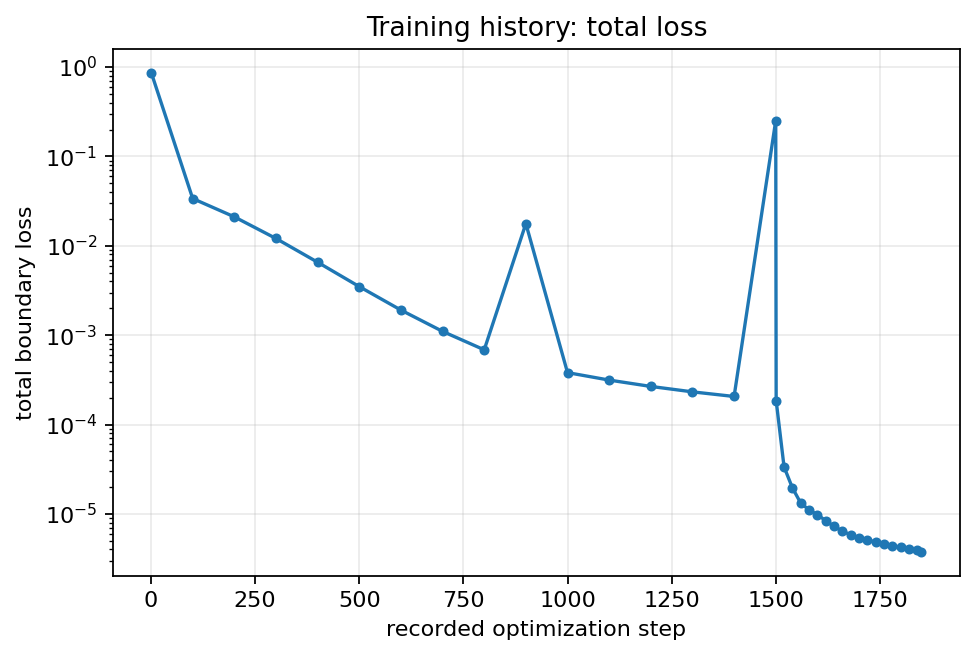

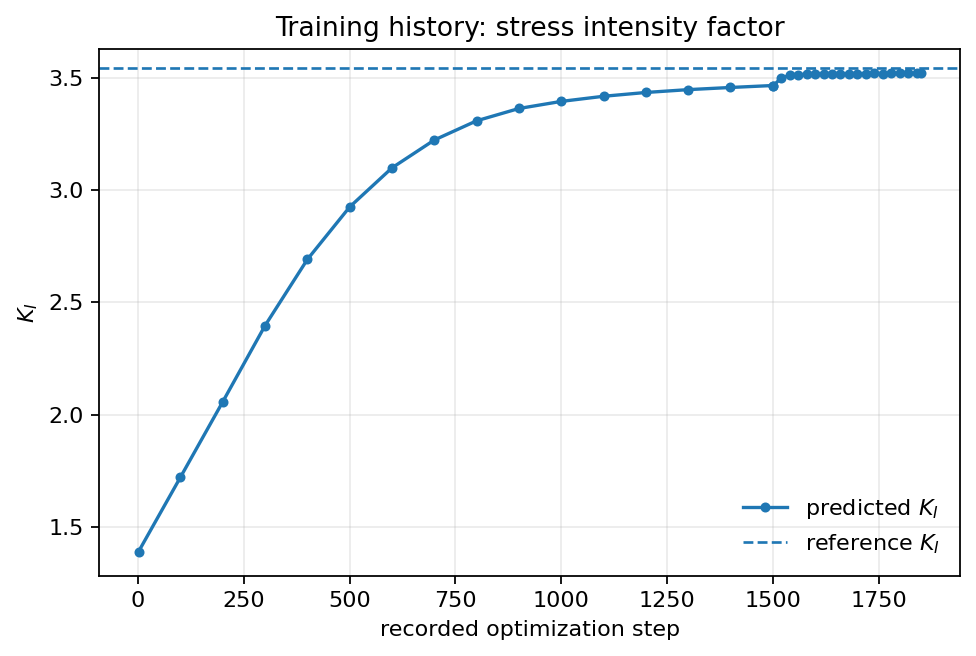

In [55]:
fig, ax = plt.subplots(figsize=(6.2, 4.2), dpi=160)

ax.semilogy(
    history["step"],
    history["total"],
    "o-",
    ms=3.5,
)

ax.set_xlabel("recorded optimization step")
ax.set_ylabel("total boundary loss")
ax.set_title("Training history: total loss")
ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(6.2, 4.2), dpi=160)

ax.plot(
    history["step"],
    history["KI"],
    "o-",
    ms=3.5,
    label="predicted $K_I$",
)

ax.axhline(
    KI_REF,
    ls="--",
    lw=1.2,
    label="reference $K_I$",
)

ax.set_xlabel("recorded optimization step")
ax.set_ylabel(r"$K_I$")
ax.set_title("Training history: stress intensity factor")
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## 16. 任意上半域点的场变量评估

In [56]:
def evaluate_upper_half(
    points: torch.Tensor,
    batch_size: int = 3000,
):
    kernel, ki = model.physical_coeffs()

    out = {q: [] for q in Q_NAMES}

    for i in range(0, points.shape[0], batch_size):
        batch = points[i:i + batch_size]

        B = build_kernel_columns(
            batch,
            src_pts,
        )

        T = build_tip_columns(batch)

        for q in Q_NAMES:
            value = B[q] @ kernel + T[q] * ki
            out[q].append(value.detach().cpu())

    return {
        q: torch.cat(values).numpy().reshape(-1)
        for q, values in out.items()
    }

## 17. 利用 Mode-I 关于 $y=0$ 的对称性恢复整块板

只对 $y$ 镜像，不对 $x$ 镜像，因为这是左边缘裂纹。

\[
u_x(x,-y)=u_x(x,y),
\]

\[
u_y(x,-y)=-u_y(x,y),
\]

\[
\sigma_{xx}(x,-y)=\sigma_{xx}(x,y),
\]

\[
\sigma_{yy}(x,-y)=\sigma_{yy}(x,y),
\]

\[
\sigma_{xy}(x,-y)=-\sigma_{xy}(x,y).
\]

In [57]:
# Full physical plate: x in [0,b], y in [-H,H].
x_full = np.linspace(
    0.0,
    b,
    cfg["nx_plot"],
)

y_full = np.linspace(
    -H,
    H,
    2 * cfg["ny_plot_half"] - 1,
)

X, Y = np.meshgrid(
    x_full,
    y_full,
)

# Map to upper half.
Xq = X.copy()
Yq = np.abs(Y)

pts_q = torch.as_tensor(
    np.column_stack(
        [
            Xq.reshape(-1),
            Yq.reshape(-1),
        ]
    ),
    dtype=torch.get_default_dtype(),
    device=device,
)

qfield = evaluate_upper_half(pts_q)

shape = X.shape

ux_q = qfield["ux"].reshape(shape)
uy_q = qfield["uy"].reshape(shape)

sxx_q = qfield["sxx"].reshape(shape)
syy_q = qfield["syy"].reshape(shape)
sxy_q = qfield["sxy"].reshape(shape)

sy_sign = np.sign(Y)

# Mode-I parity.
ux_full = ux_q
uy_full = sy_sign * uy_q

sxx_full = sxx_q
syy_full = syy_q
sxy_full = sy_sign * sxy_q

# sigma_zz and von Mises.
if cfg["plane_strain"]:
    szz_full = nu * (sxx_full + syy_full)
else:
    szz_full = np.zeros_like(sxx_full)

von_mises = np.sqrt(
    0.5 * (
        (sxx_full - syy_full) ** 2
        + (syy_full - szz_full) ** 2
        + (szz_full - sxx_full) ** 2
        + 6.0 * sxy_full**2
    )
)

print("raw max |sxx| =", np.nanmax(np.abs(sxx_full)))
print("raw max |syy| =", np.nanmax(np.abs(syy_full)))
print("raw max |sxy| =", np.nanmax(np.abs(sxy_full)))
print("raw max VM    =", np.nanmax(von_mises))

raw max |sxx| = 44390191.69910278
raw max |syy| = 44390192.109132305
raw max |sxy| = 6.641467272749253
raw max VM    = 17756076.761647023


## 18. 全场应力云图

为了避免裂尖 $r^{-1/2}$ 奇异值把色标撑爆，这里使用百分位显示范围并用 `np.clip()` 截断**绘图值**。

colorbar 不使用 `extend`，因此是普通平头矩形色标。

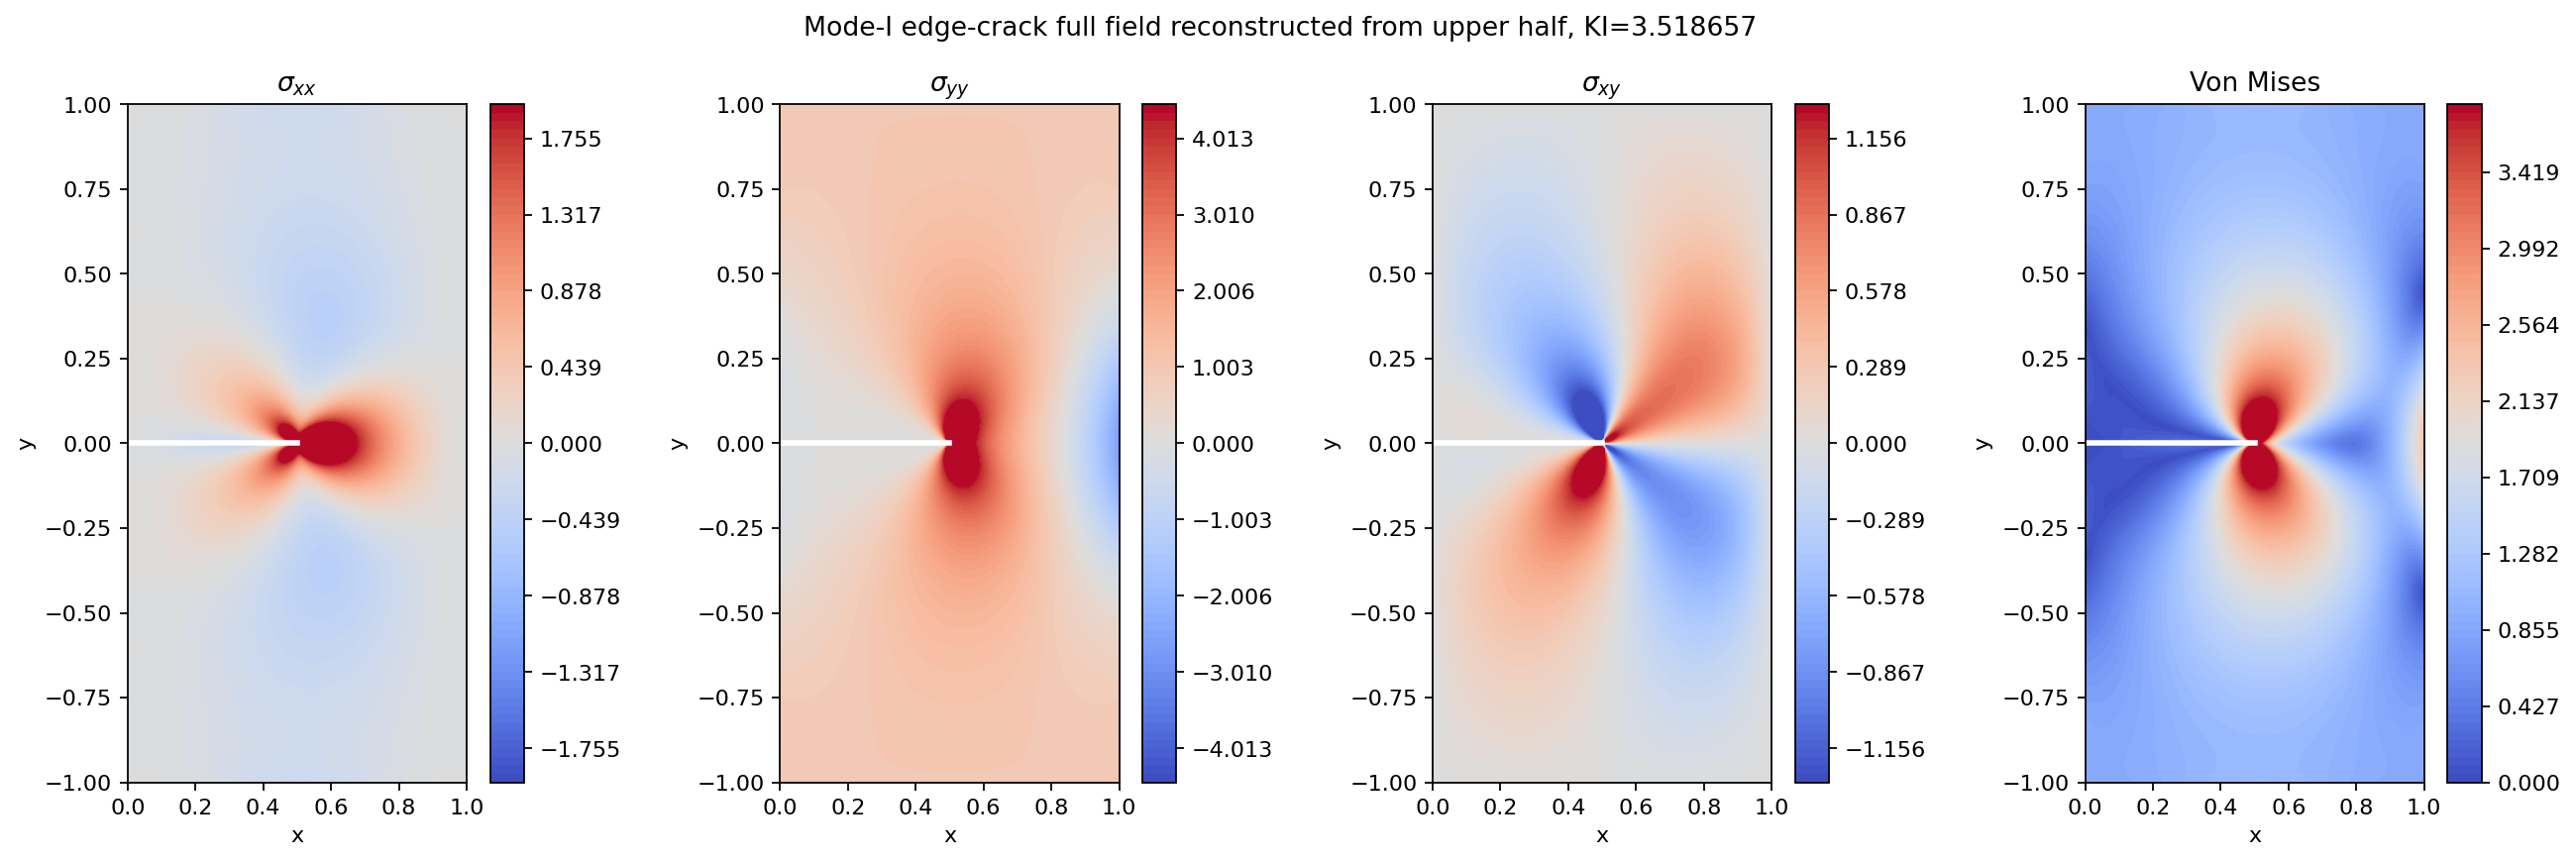

In [58]:
plot_percentile = cfg["plot_percentile"]

fields = [
    (sxx_full, r"$\sigma_{xx}$", True),
    (syy_full, r"$\sigma_{yy}$", True),
    (sxy_full, r"$\sigma_{xy}$", True),
    (von_mises, "Von Mises", False),
]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16.5, 5.5),
    dpi=160,
)

for ax, (field, title, signed_field) in zip(axes, fields):

    if signed_field:
        vmax = np.nanpercentile(
            np.abs(field),
            plot_percentile,
        )

        vmin = -vmax

        field_show = np.clip(
            field,
            vmin,
            vmax,
        )

        levels = np.linspace(
            vmin,
            vmax,
            81,
        )

    else:
        vmin = 0.0

        vmax = np.nanpercentile(
            field,
            plot_percentile,
        )

        field_show = np.clip(
            field,
            vmin,
            vmax,
        )

        levels = np.linspace(
            vmin,
            vmax,
            81,
        )

    # No "extend" -> flat rectangular colorbar.
    cf = ax.contourf(
        X,
        Y,
        field_show,
        levels=levels,
        cmap="coolwarm",
    )

    fig.colorbar(
        cf,
        ax=ax,
    )

    # Edge crack from x=0 to x=a.
    ax.plot(
        [0.0, a],
        [0.0, 0.0],
        "w-",
        lw=2.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)

fig.suptitle(
    f"Mode-I edge-crack full field reconstructed from upper half, "
    f"KI={KI_pred:.6f}"
)

fig.tight_layout()
plt.show()

## 19. 裂尖正前方 $K_I$ 近场验证

对于 I 型裂纹，在 $\theta=0$：

\[
\sigma_{yy}(r,0)
\sim
\frac{K_I}{\sqrt{2\pi r}}.
\]

因此

\[
K_I^{\rm local}(r)
=
\sigma_{yy}(r,0)\sqrt{2\pi r}
\]

在适当近场范围内应接近训练得到的 $K_I$。

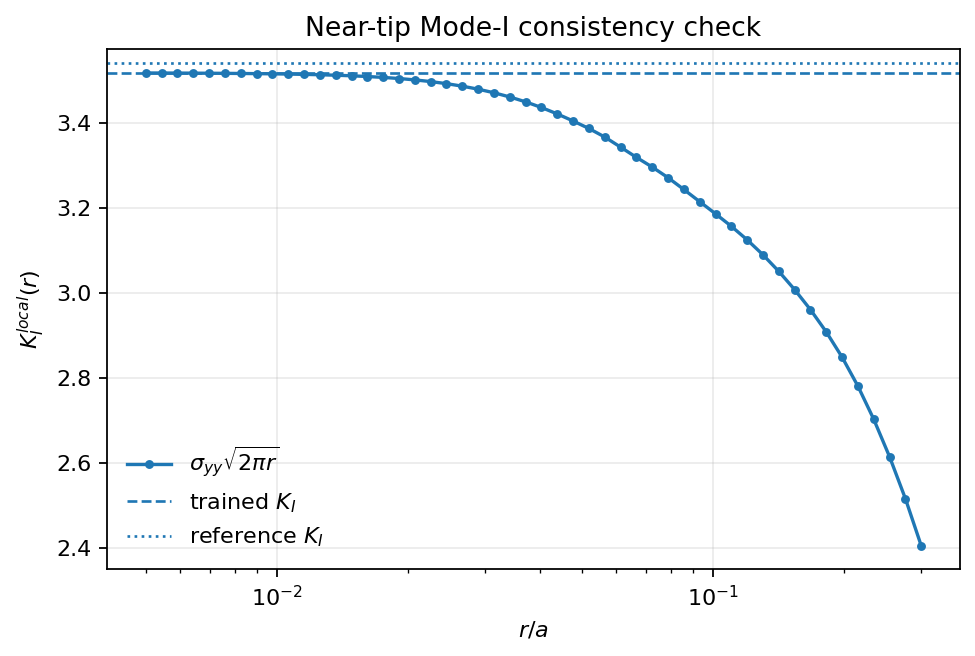

In [59]:
r_check = np.geomspace(
    5.0e-3 * a,
    0.30 * a,
    50,
)

x_check = a + r_check

pts_check = torch.as_tensor(
    np.column_stack(
        [
            x_check,
            np.zeros_like(x_check),
        ]
    ),
    dtype=torch.get_default_dtype(),
    device=device,
)

field_check = evaluate_upper_half(
    pts_check
)

syy_check = field_check["syy"]

KI_local = (
    syy_check
    * np.sqrt(
        2.0 * np.pi * r_check
    )
)

fig, ax = plt.subplots(
    figsize=(6.2, 4.2),
    dpi=160,
)

ax.semilogx(
    r_check / a,
    KI_local,
    "o-",
    ms=3.0,
    label=r"$\sigma_{yy}\sqrt{2\pi r}$",
)

ax.axhline(
    KI_pred,
    ls="--",
    lw=1.2,
    label="trained $K_I$",
)

ax.axhline(
    KI_REF,
    ls=":",
    lw=1.2,
    label="reference $K_I$",
)

ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$K_I^{local}(r)$")
ax.set_title("Near-tip Mode-I consistency check")
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## 20. 使用说明

### 改裂纹长度
修改：

```python
cfg["a"]
```

并保证 $0<a<b$。

### 改板宽与总高度
修改：

```python
cfg["b"]
cfg["h"]
```

代码自动使用 $H=h/2$。

### 改成两圈裂尖局部源

```python
"tip_cluster_radii": [0.08, 0.16]
```

### 做公平对比
若要和中心裂纹算例比较训练时间/参数量，建议统一：

- `n_src_side`
- `tip_cluster_count`
- `tip_cluster_radii`
- Adam / L-BFGS 步数
- 边界配点数量级
- `lambda_reg`

### 参考解提醒
当前 `reference_ki_edge()` 是常用有限宽度单边裂纹近似。
如果 Fig.10 对应论文给出了专门的 $K_I$ 参考公式或固定的 $a/b,h/b$，最终论文结果应优先采用原文参考。